# Лабораторная работа №4
## Линейная регрессия

### Метод

Модель имеет вид $\hat{y} = ax + b$, где $x$ — длина лепестка, $\hat{y}$ — предсказанная
ширина, $a$ — коэффициент наклона, $b$ — свободный член.
Метод наименьших квадратов подбирает $a$ и $b$, минимизируя
$\sum_{i=1}^{n}(y_i - (ax_i + b))^2$ по всем исходным данным.
Прямая описывает общую зависимость и не обязана проходить через каждую точку.

Выполните ячейки сверху вниз. Последняя ячейка с кодом запросит число с клавиатуры.
Сохранённые результаты соответствуют примеру ввода `4.5` см.

### Установка библиотек

Если библиотеки ещё не установлены, выполните в отдельной ячейке Jupyter:

```python
%pip install numpy matplotlib scikit-learn
```


In [12]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_iris
from sklearn.linear_model import LinearRegression


### 1. Данные

In [13]:
iris = load_iris()
X = iris.data[:, [2]]  # Длина лепестка: матрица с одним столбцом.
y = iris.data[:, 3]    # Ширина лепестка.

print(f"Количество наблюдений: {len(y)}")
print(f"Длина лепестка: от {X.min():.1f} до {X.max():.1f} см")
print(f"Ширина лепестка: от {y.min():.1f} до {y.max():.1f} см")


Количество наблюдений: 150
Длина лепестка: от 1.0 до 6.9 см
Ширина лепестка: от 0.1 до 2.5 см


### 2. Построение прямой

Подберём коэффициенты линейной регрессии по всем исходным данным и выведем уравнение прямой.


In [14]:
model = LinearRegression()
model.fit(X, y)

print(f"Уравнение: y = {model.coef_[0]:.3f} * x {model.intercept_:+.3f}")


Уравнение: y = 0.416 * x -0.363


### 3. Визуализация

На графике показаны исходные данные и прямая регрессии.
Одна функция используется для общего графика и графика с пользовательским прогнозом.


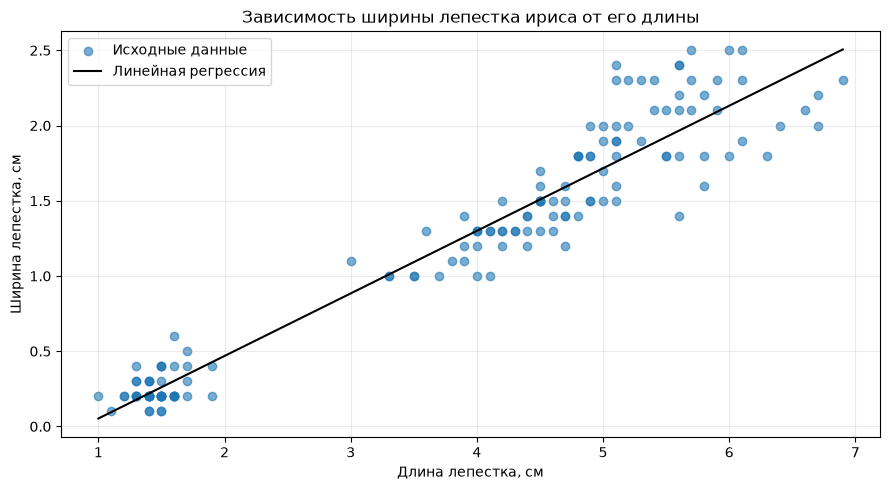

In [15]:
def plot_regression(length=None, width=None):
    left, right = X.min(), X.max()
    if length is not None:
        left, right = min(left, length), max(right, length)
    x_line = np.linspace(left, right, 200).reshape(-1, 1)

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.scatter(X[:, 0], y, alpha=0.6, label="Исходные данные")
    ax.plot(x_line[:, 0], model.predict(x_line), color="black", label="Линейная регрессия")

    if length is not None:
        ax.scatter(
            length, width, color="crimson", marker="*", s=220,
            zorder=5, label=f"Прогноз: ({length:.2f}; {width:.2f}) см"
        )

    ax.set_title("Зависимость ширины лепестка ириса от его длины")
    ax.set_xlabel("Длина лепестка, см")
    ax.set_ylabel("Ширина лепестка, см")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    plt.show()


plot_regression()


### 4. Предсказание по введённой длине

Введите длину лепестка в сантиметрах, например `4.5` или `4,5`.
При некорректном вводе программа попросит повторить его.
За пределами диапазона исходных данных получится экстраполяция, которая может быть ненадёжной.
Для другого прогноза повторно выполните следующую ячейку.


Внимание: длина вне диапазона данных. Это экстраполяция.
При длине 100.00 см предсказанная ширина: 41.21 см


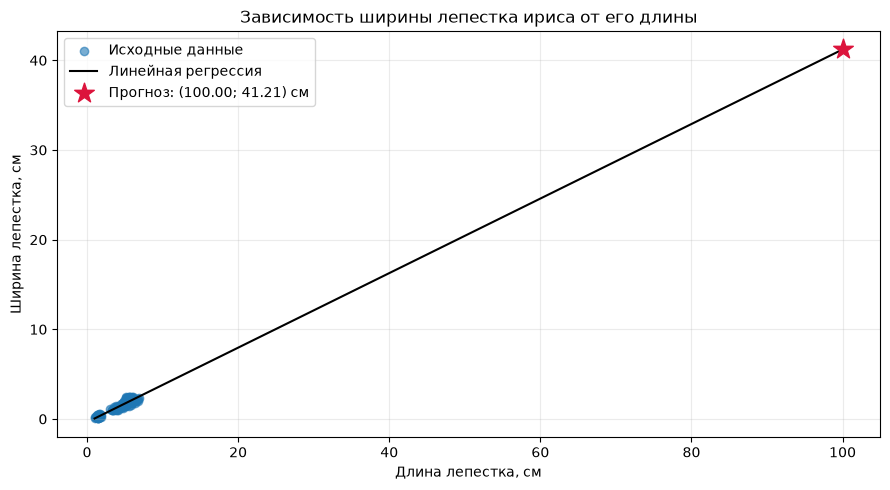

In [16]:
while True:
    try:
        length = float(input("Введите длину лепестка в см: ").replace(",", "."))
    except ValueError:
        print("Введите число, например 4.5.")
        continue

    if not np.isfinite(length) or length <= 0:
        print("Длина должна быть конечным положительным числом.")
        continue
    break

if not X.min() <= length <= X.max():
    print("Внимание: длина вне диапазона данных. Это экстраполяция.")

width = model.predict([[length]])[0]
print(f"При длине {length:.2f} см предсказанная ширина: {width:.2f} см")
if width <= 0:
    print("Модель дала неположительную ширину: такой прогноз физически не имеет смысла.")
plot_regression(length, width)
